# What does San Francisco pay its people?

An analysis of the City and County of San Francisco's public employee compensation records (DataSF), and a model that estimates what a **role** pays.

**Approach in one line:** clean the data carefully, ask a question the data can honestly answer, test the model on a future year it has never seen, and compare it with a simple baseline.

The pipeline lives in `src/` and this notebook walks through it:

| Step | Script | Output |
|---|---|---|
| Clean | `python -m src.clean` | `data/processed/compensation.parquet` |
| Model | `python -m src.train` | `models/`, `reports/` |
| Insights | `python -m src.insights` | `app_data/` (feeds the Streamlit app) |

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.options.display.float_format = "{:,.2f}".format

## 1. The raw data has three traps

The export has one row per employee per year, with six pay components and the organisational context of the job.

In [2]:
raw = pd.read_csv(ROOT / "data" / "Employee_Compensation.csv", low_memory=False)
print(f"{len(raw):,} rows, {raw.shape[1]} columns")
raw.groupby(["Year", "Year Type"]).size().unstack().fillna(0).astype(int)

799,562 rows, 22 columns


Year Type,Calendar,Fiscal
Year,,
2013,39904,39476
2014,41423,40868
2015,42989,43078
2016,44391,44087
2017,42112,42188
2018,42820,42819
2019,44525,44528
2020,40940,42376
2021,40156,39931


**Trap 1: every employee appears twice per year.** Each person is listed once for the calendar year and once for the fiscal year. Mixing both double counts people. It also lets near-identical rows land in both the training and the test set. The cleaned data keeps **fiscal years only**.

In [3]:
parts = ["Salaries", "Overtime", "Other Salaries", "Retirement", "Health and Dental", "Other Benefits"]
identity = (raw[parts].sum(axis=1) - raw["Total Compensation"]).abs() < 1
print(f"Total Compensation == sum of the six components on {identity.mean():.1%} of rows")

Total Compensation == sum of the six components on 100.0% of rows


**Trap 2: the target is the sum of six columns.** Any model that sees those columns can reach R² ≈ 1.0 just by adding them up. So the model here uses **only role information**: job title, job family, department, organisation group, union and year.

In [4]:
fiscal = raw[raw["Year Type"] == "Fiscal"]
print("Department names:", fiscal["Department"].nunique(), "| department codes:", fiscal["Department Code"].nunique())
print("Job titles:      ", fiscal["Job"].nunique(), "| job codes:       ", fiscal["Job Code"].nunique())
fiscal[fiscal["Department Code"] == "DPH"].groupby("Department")["Year"].agg(["min", "max"])

Department names: 108 | department codes: 60
Job titles:       1359 | job codes:        1221


,min,max
Department,,
DPH Public Health,2013,2016
Public Health,2017,2022


**Trap 3: names changed, codes did not.** Departments were renamed in 2017 ("DPH Public Health" became "Public Health"), so grouping by name splits one department in two. The cleaning step keys everything on **codes** and gives each code its most recent name.

## 2. Cleaning

See `src/clean.py`. Key decisions:

* fiscal years only
* codes as keys, with the latest name for each code
* real zeros stay zero (most employees have no overtime, and that is information, not a missing value)
* part-year / part-time records are **flagged** with `is_full_year` (base salary at least half the job's median that year, and at least $15k), not deleted
* incomplete years are flagged (see below)

In [5]:
df = pd.read_parquet(ROOT / "data" / "processed" / "compensation.parquet")
print(f"{len(df):,} fiscal records | {int(df.is_full_year.sum()):,} full-year")
print(f"{df.department_code.nunique()} departments, {df.job_code.nunique()} job titles, {df.union_code.nunique()} unions")

420,056 fiscal records | 322,727 full-year
60 departments, 1221 job titles, 71 unions


### A data quality catch: FY2022 is incomplete

When I plotted the components by year, FY2022 total pay *fell*. The cause: health & dental is $0 for almost every FY2022 record in this export, so FY2022 totals are understated. Any year like this is flagged and left out of modelling and trends.

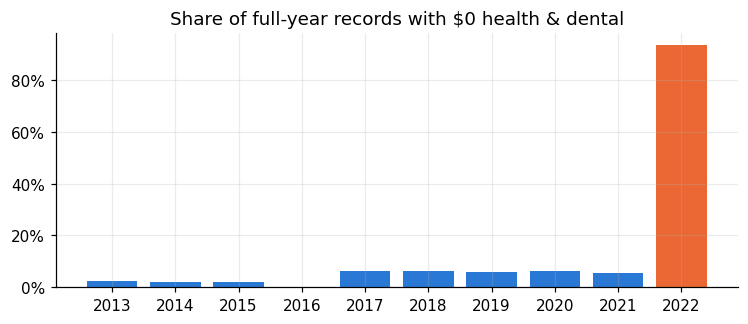

In [6]:
fy = df[df.is_full_year]
zero_hd = (fy.health_and_dental == 0).groupby(fy.year).mean()

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(zero_hd.index, zero_hd.values, color=[ORANGE if v > .5 else BLUE for v in zero_hd.values])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Share of full-year records with $0 health & dental")
ax.set_xticks(zero_hd.index)
plt.show()

## 3. What the data says

All figures below are for **full-year employees in complete fiscal years** (see `src/insights.py`).

In [7]:
H = json.loads((ROOT / "app_data" / "headline.json").read_text())
trend = pd.read_csv(ROOT / "app_data" / "pay_trend.csv")
ot = pd.read_csv(ROOT / "app_data" / "overtime_by_department.csv")
gaps = pd.read_csv(ROOT / "app_data" / "same_job_gaps.csv", dtype={"job_code": str})

print(f"Median total comp FY{H['first_year']}: ${H['median_total_first']:,.0f}  ->  FY{H['latest_complete_year']}: ${H['median_total_latest']:,.0f}  (+{H['growth_total_pct']:.0%})")
print(f"Yearly growth: base salary {H['cagr_base']:.1%}, benefits {H['cagr_benefits']:.1%}")

Median total comp FY2013: $116,031  ->  FY2021: $151,773  (+31%)
Yearly growth: base salary 3.3%, benefits 4.0%


### Finding 1: benefits are growing faster than pay

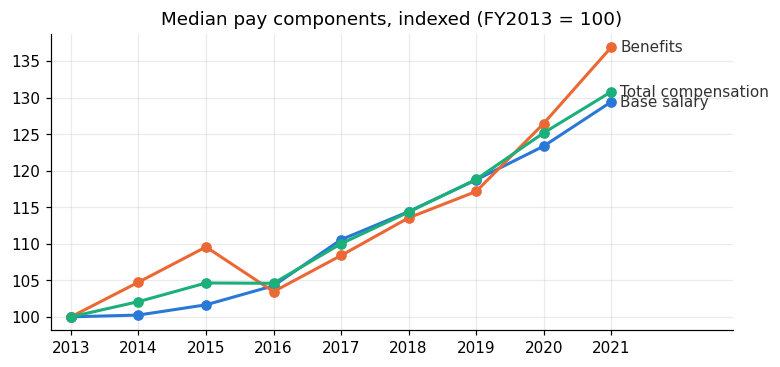

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for col, name, color in [("index_base", "Base salary", BLUE), ("index_benefits", "Benefits", ORANGE),
                         ("index_total", "Total compensation", AQUA)]:
    ax.plot(trend.year, trend[col], marker="o", lw=2, color=color, label=name)
    ax.annotate(name, (trend.year.iloc[-1], trend[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color="#333")
ax.set_title(f"Median pay components, indexed (FY{H['first_year']} = 100)")
ax.set_xticks(trend.year); ax.set_xlim(trend.year.min() - .3, trend.year.max() + 1.8)
plt.show()

### Finding 2: overtime is concentrated in public safety

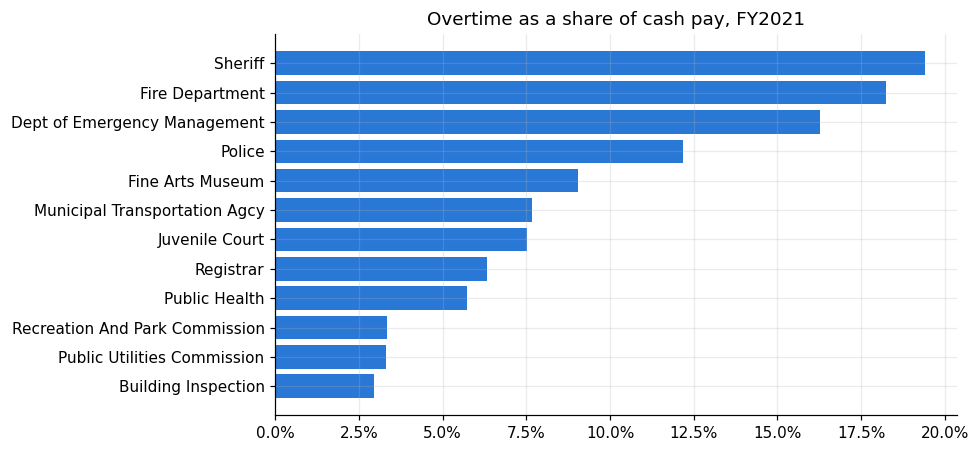

,department,employees,overtime_share_of_cash_pay,share_ot_over_25pct_of_base,overtime_total_musd
0,Sheriff,1000,0.19,0.39,28.66
1,Fire Department,1713,0.18,0.40,55.24
2,Dept of Emergency Management,272,0.16,0.32,6.32
3,Police,2854,0.12,0.18,52.34
4,Fine Arts Museum,98,0.09,0.15,0.76


In [9]:
top = ot.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.department, top.overtime_share_of_cash_pay, color=BLUE)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title(f"Overtime as a share of cash pay, FY{H['latest_complete_year']}")
plt.show()
ot.head(5)[["department", "employees", "overtime_share_of_cash_pay", "share_ot_over_25pct_of_base", "overtime_total_musd"]]

### Finding 3: same job, same pay (mostly)

For job titles held by at least 15 full-year employees in two or more departments, the median pay gap between departments is small. SF pays by **job classification**, not by department. The largest gaps are listed below. Some come from overtime and some from different mixes of seniority or part-time staff.

In [10]:
print(f"{H['jobs_in_multiple_departments']} jobs in 2+ departments; median gap in total comp {H['median_gap_pct_total']:.1%}, in base salary {H['median_gap_pct_base']:.1%}")
gaps.head(8)[["job", "departments", "employees", "low_total", "high_total", "total_gap_pct", "base_gap_pct"]]

45 jobs in 2+ departments; median gap in total comp 2.7%, in base salary 2.0%


,job,departments,employees,low_total,high_total,total_gap_pct,base_gap_pct
0,Attorney (Civil/Criminal),3,328,"218,345.38","294,302.33",0.35,0.42
1,Clerk,3,177,"26,605.12","100,617.18",2.78,2.39
2,Public Service Trainee,4,89,"25,067.05","85,270.82",2.40,1.88
3,Technology Expert I,2,36,"187,085.88","234,438.06",0.25,0.29
4,Junior Clerk,2,64,"22,103.09","62,680.34",1.84,0.95
5,Public Svc Aide-Public Works,2,116,"27,253.63","62,883.81",1.31,1.01
6,Sr Community Dev Spec 2,2,39,"171,179.05","191,229.65",0.12,0.05
7,Automotive Mechanic,2,158,"147,238.57","165,302.49",0.12,0.00


## 4. The model

**Question:** given only a role (job title, job family, department, organisation group, union, year), what total compensation should you expect?

**Design** (see `src/train.py`):

* **Time-based test.** Train on FY2013-2020, test on FY2021. Early stopping uses FY2020 and the test year is never touched until the end.
* **Pay level vs. pay structure.** City-wide pay rises every year and tree models can't extrapolate. A pay index (median total comp per year, projected on a log-linear trend) carries the level. LightGBM learns each role's pay *relative* to that index.
* **Native categorical handling** in LightGBM for 1,000+ job titles, with no arbitrary label encoding.
* **Ranges, not just points.** 10th and 90th percentile models give an 80% range. The range is stretched by a factor calibrated on FY2020 so it really covers about 80% of people.
* **Baselines.** Any model has to beat (a) the city-wide median and (b) last year's median for the job title, grown by the pay trend.

In [11]:
comp = pd.read_csv(ROOT / "reports" / "model_comparison.csv", index_col=0)
comp

,R2,MAE,MedAPE,within_10pct,coverage_80
City-wide median,-0.06,"50,340.33",0.26,0.21,NaN
"Job title median (last year, grown)",0.78,"19,945.31",0.08,0.59,NaN
LightGBM (this model),0.78,"19,815.86",0.08,0.60,0.83


**Reading the results honestly.** The role explains about 78% of the variation in pay, with a median error of under 8%. But a simple lookup of last year's median for the job title does almost exactly as well.

That is the main finding. San Francisco sets pay by job classification and union agreement. Most of what is left is individual: overtime hours, seniority steps and time on leave. No role-level model can see those. The model's added value is the **calibrated range** (83% coverage on an unseen year), estimates for any job / department / union combination, and an explanation of what drives each estimate.

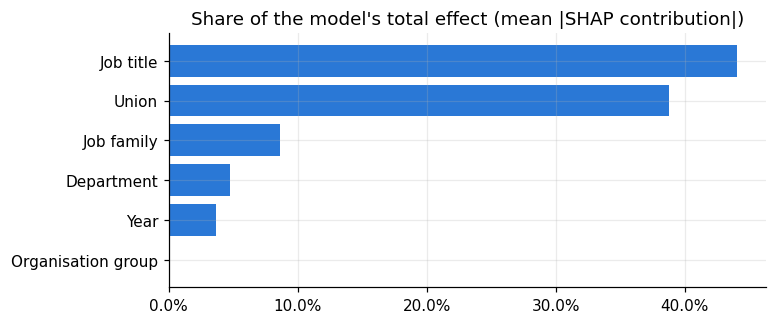

In [12]:
imp = pd.read_csv(ROOT / "reports" / "feature_importance.csv").iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(imp.feature, imp.share, color=BLUE)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Share of the model's total effect (mean |SHAP contribution|)")
plt.show()

Job title and union dominate. They overlap heavily, because many unions represent a single occupation group (firefighters, nurses, police). So the split between them should not be read as causal.

Where is the model least accurate? Roles with a lot of overtime or shift pay:

In [13]:
err = pd.read_csv(ROOT / "reports" / "error_by_job_family.csv")
pd.concat([err.head(4), err.tail(4)])

,job_family,n,MedAPE
0,Health & Sanitation Inspection,127,0.04
1,Untitled,475,0.04
2,Management,1139,0.04
3,Hospital Administration,143,0.05
39,Nursing,3519,0.14
40,Dietary & Food,249,0.16
41,Medical & Dental,237,0.18
42,Public Service Aide,354,0.19


## 5. Limitations and next steps

* **No hours worked.** "Full year" is a proxy based on base salary.
* **No seniority or tenure.** This is deliberate (the estimate is for a role, not a person), and it is why R² stops near 0.78.
* **FY2022 excluded** in this export because benefits were not yet posted. Newer DataSF exports go up to FY2026. Dropping a fresh export into `data/` and rerunning the three scripts updates everything.
* **Next:** add overtime as a separate prediction target, since it is the main source of individual variation, and compare SF pay against private-sector benchmarks for similar occupations.